In [82]:
import numpy as np
import matplotlib.pyplot as plt

In [83]:
size = 256
d = 20
fs = 1e6  # Sampling frequency in Hz
Ts = 1/fs  # Sampling period in seconds
time = np.arange(size + d) * Ts  # Time vector
phi_0 = 0  # Initial phase
alpha_0 = 0.2  # Amplitude

Fd = 1e4  # Doppler frequency in Hz
phase_shift = np.exp(1j * (2 * np.pi * Fd * time + phi_0)) # Phase shift due to Doppler effect
R = np.random.choice([-1,1], size = size)

V = (alpha_0 * phase_shift)*np.append(np.zeros(d), R) 
C = np.correlate(V, R, mode = 'full')

e_doppler = np.argmax(np.abs(C)) - (len(R) -1)
print(f"Estimated delay with Doppler effect: {e_doppler}, Actual delay: {d}")   


Estimated delay with Doppler effect: 20, Actual delay: 20


In [84]:
V_compensated = np.exp(-1j * (2 * np.pi * Fd * time))*V
C_compensated = np.correlate(V_compensated, R, mode = 'full')
e_compensated = np.argmax(np.abs(C_compensated)) - (len(R) -1)
print(f"Estimated delay after compensation: {e_compensated}, Actual delay: {d}")

Estimated delay after compensation: 20, Actual delay: 20


In [85]:
possible_fd = np.arange(-20e3, 20e3+1, 1e3)  # Possible Doppler frequencies to test

possible_correlations = np.zeros((len(possible_fd), len(C)), dtype=complex)
peak_values = np.zeros(len(possible_fd))

for i,fd in enumerate(possible_fd):
    V_test = np.exp(-1j * (2 * np.pi * fd * time))*V
    C_test = np.correlate(V_test, R, mode = 'full')
    possible_correlations[i, :] = C_test    
    peak_values[i] = np.max(np.abs(C_test))

# Find the Doppler frequency that gives the highest peak value
aux = np.argmax(np.abs(possible_correlations))
best_fd_idx = aux // len(C)
best_fd = possible_fd[best_fd_idx]
delay_estimate = np.argmax(np.abs(possible_correlations[best_fd_idx, :])) - (len(R) -1)
print(f"Estimated Doppler frequency: {best_fd} Hz")
print(f"Estimated delay after Doppler compensation: {delay_estimate}, Actual delay: {d}")


Estimated Doppler frequency: 10000.0 Hz
Estimated delay after Doppler compensation: 20, Actual delay: 20


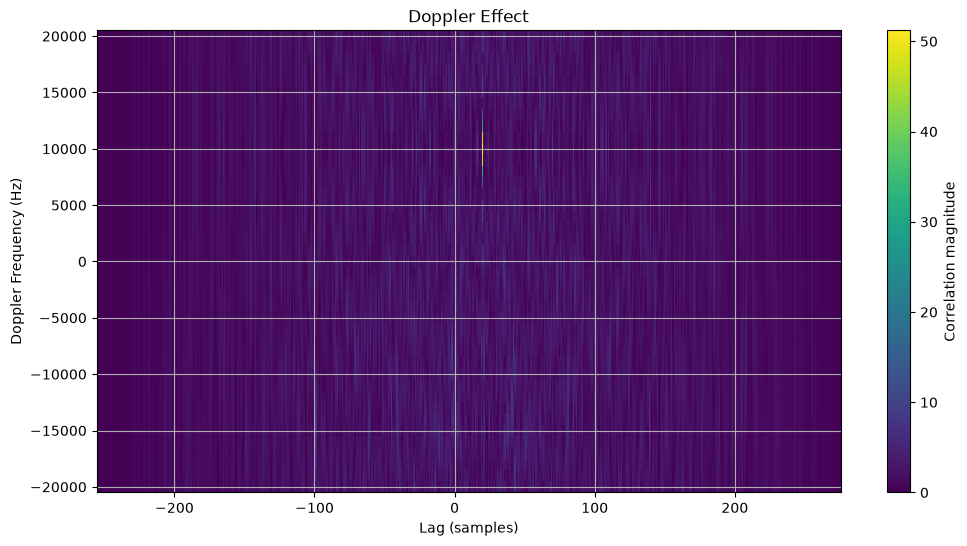

In [86]:
lag = np.arange(len(possible_correlations[best_fd_idx, :])) - len(R) + 1
plt.figure(figsize=(12, 6))
plt.pcolormesh(lag, possible_fd, np.abs(possible_correlations), shading='auto')
plt.xlabel('Lag (samples)')
plt.ylabel('Doppler Frequency (Hz)')
plt.title('Doppler Effect')
plt.colorbar(label='Correlation magnitude')
plt.grid(True)

In [87]:
size_res = 2000
time_res = np.arange(size_res + d) * Ts  # Time vector for resolution
phase_shift_res = np.exp(1j * (2 * np.pi * Fd * time_res + phi_0)) # Phase shift due to Doppler effect
R_res = np.random.choice([-1,1], size = size_res)

V_res = (alpha_0 * phase_shift_res)*np.append(np.zeros(d), R_res)

C_res = np.correlate(V_res, R_res, mode = 'full')
e_doppler_res = np.argmax(np.abs(C_res)) - (len(R_res) -1)
print(f"Estimated delay with Doppler effect (high resolution): {e_doppler_res}, Actual delay: {d}")




Estimated delay with Doppler effect (high resolution): 203, Actual delay: 20


In [88]:
possible_fd_res = np.arange(-20e3, 20e3+1, 125)  # Possible Doppler frequencies to test



possible_correlations_res = np.zeros((len(possible_fd_res), len(C_res)), dtype=complex)
peak_values_res = np.zeros(len(possible_fd_res))

for i,fd in enumerate(possible_fd_res):
    V_test_res = np.exp(-1j * (2 * np.pi * fd * time_res))*V_res
    C_test_res = np.correlate(V_test_res, R_res, mode = 'full')
    possible_correlations_res[i, :] = C_test_res    
    peak_values_res[i] = np.max(np.abs(C_test_res))

# Find the Doppler frequency that gives the highest peak value
aux_res = np.argmax(np.abs(possible_correlations_res))
best_fd_idx_res = aux_res // len(C_res)
best_fd_res = possible_fd_res[best_fd_idx_res]
delay_estimate_res = np.argmax(np.abs(possible_correlations_res[best_fd_idx_res, :])) - (len(R_res) -1)
print(f"Estimated Doppler frequency: {best_fd_res} Hz")
print(f"Estimated delay after Doppler compensation: {delay_estimate_res}, Actual delay: {d}")


Estimated Doppler frequency: 10000.0 Hz
Estimated delay after Doppler compensation: 20, Actual delay: 20


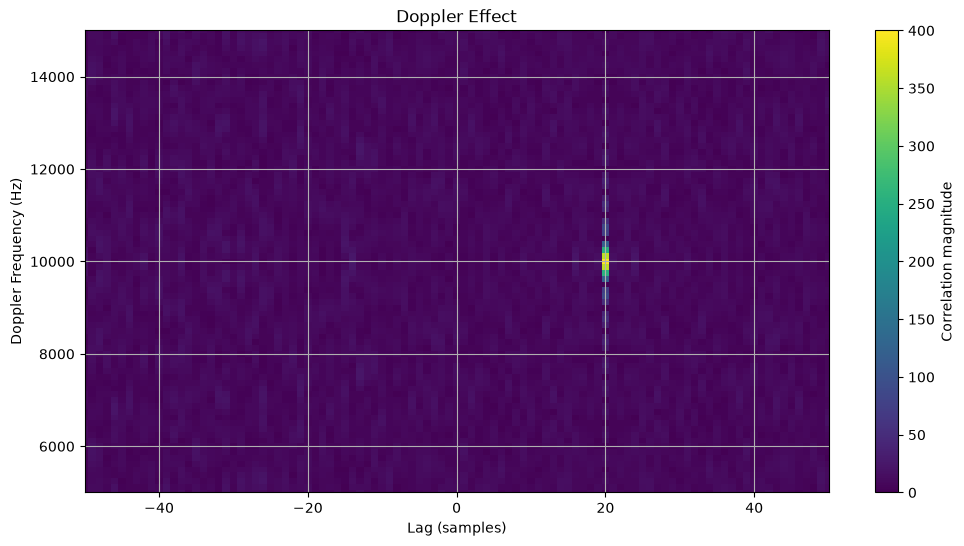

In [89]:
lag_res = np.arange(len(possible_correlations_res[best_fd_idx_res, :])) - len(R_res) + 1
plt.figure(figsize=(12, 6))
plt.pcolormesh(lag_res, possible_fd_res, np.abs(possible_correlations_res), shading='auto')
plt.xlabel('Lag (samples)')
plt.ylabel('Doppler Frequency (Hz)')
plt.title('Doppler Effect')
plt.colorbar(label='Correlation magnitude')
plt.xlim(-50, 50)
plt.ylim(5e3, 15e3)
plt.grid(True)

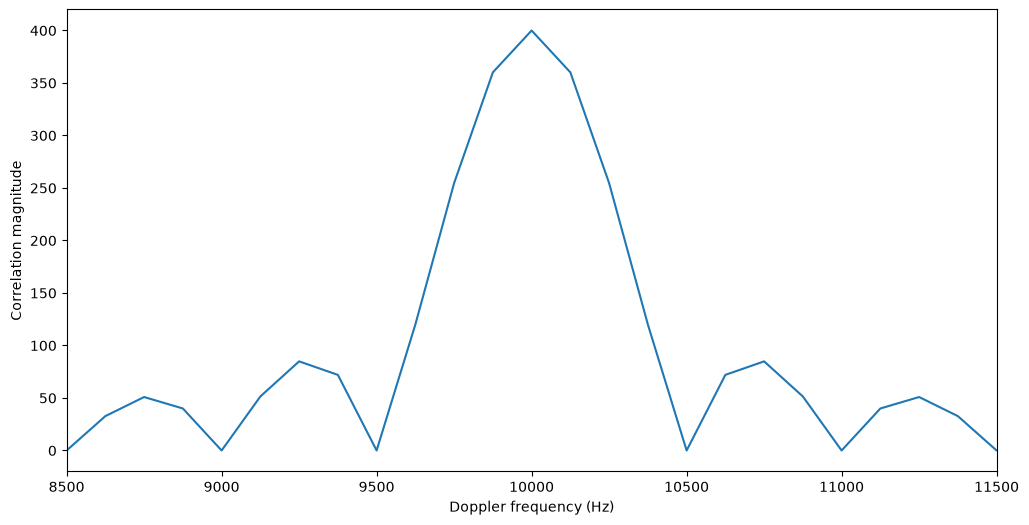

In [91]:
best_delay_idx_res = aux_res % len(C_res)

plt.figure(figsize=(12, 6))
plt.plot(
    possible_fd_res,
    np.abs(possible_correlations_res[:, best_delay_idx_res])
)
plt.xlabel('Doppler frequency (Hz)')
plt.ylabel('Correlation magnitude')
plt.xlim(8500, 11500)
plt.show()